# 07 — фаза 7: SSL v2 (EXPLORATORY)

Ноутбук лише читає `reports/tables/phase7_*.csv`. Позначення: b1 = `ssl_v2_b`, b2 = `ssl_v2_b_seed43`, cont1 = `ssl_v2_cont`,
cont2 = `ssl_v2_cont_seed43`. Вибір енкодера — на val. Деталі: `reports/phase7_summary.md`,
`reports/phase7_seed2_summary.md`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from malaria_ssl.detr.compare import plot_paired_diffs
from malaria_ssl.utils.config import resolve_path

T = resolve_path('reports/tables')
F = resolve_path('reports/figures')


def ci(v, lo, hi):
    return f'{v:.3f} [{lo:.3f}, {hi:.3f}]'


def wide(df, index, columns, v='value', lo='ci_low', hi='ci_high'):
    """Long table of value + CI -> formatted pivot."""
    d = df.assign(s=[ci(a, b, c) for a, b, c in zip(df[v], df[lo], df[hi])])
    return d.pivot(index=index, columns=columns, values='s')


## ViT-DETR наскрізний: test infected AP50 за seed

v2_b у DETR не перевищив DINO (критерій 2 не виконано).

In [2]:
r = pd.read_csv(T / 'phase7_detr_runs.csv')
r['model'] = r['run'].str.replace(r'_seed4[34]$', '', regex=True)
r['seed'] = r['run'].str.extract(r'seed(4[34])$')[0].fillna('42')
t = r.pivot(index='model', columns='seed', values='test_AP50_infected')
t.assign(mean=t.mean(axis=1), std=t.std(axis=1)).round(3)

seed,42,43,44,mean,std
model,,,,,
a_coco_detr_binary,0.551,0.583,0.517,0.550,0.033
b_vit_dino_full,0.614,0.644,0.601,0.620,0.022
b_vit_imagenet,0.528,0.657,0.517,0.567,0.078
b_vit_v2_b,0.560,0.570,0.598,0.576,0.020


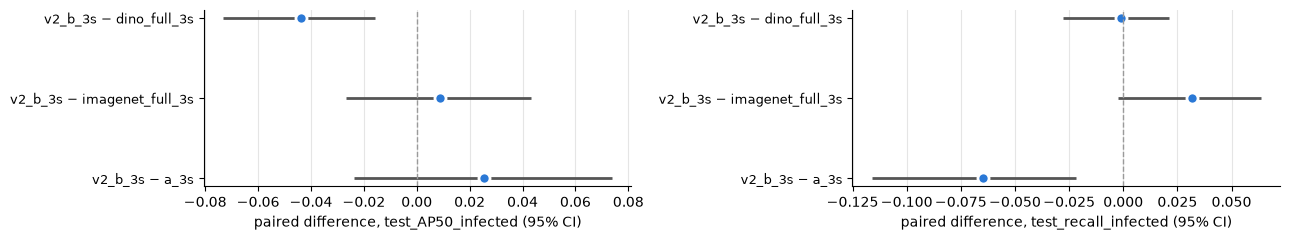

In [3]:
d = pd.read_csv(T / 'phase7_detr_diff.csv')
d = d[d['a'] == 'v2_b_3s']
fig, axes = plt.subplots(1, 2, figsize=(13, 2.5))
plot_paired_diffs(d, 'test_AP50_infected', axes[0])
plot_paired_diffs(d, 'test_recall_infected', axes[1])
plt.tight_layout()

## Двоетапна схема: бокси A + лінійний класифікатор на заморожених ознаках

Середнє 3 seed боксів, навчання на чистих кропах.

In [4]:
s = pd.read_csv(T / 'phase7_two_stage_seed2.csv')
s = s[(s['run'] == 'a_3s') & s['training'].isin(['clean', '-'])]
t = s[s['split'] == 'test'].set_index('encoder')
out = pd.DataFrame({'val AP50': s[s['split'] == 'val'].set_index('encoder')['AP50'].round(3),
                    'test AP50': [ci(*x) for x in zip(t['AP50'], t['AP50_lo'], t['AP50_hi'])],
                    'precision': t['precision'].round(3), 'recall': t['recall'].round(3)}, index=t.index)
out.sort_values('test AP50', ascending=False)

,val AP50,test AP50,precision,recall
encoder,,,,
ssl_v2_b_seed43,0.795,"0.773 [0.723, 0.820]",0.862,0.409
ssl_v2_b,0.795,"0.751 [0.704, 0.802]",0.813,0.509
ssl_v2_cont,0.791,"0.711 [0.661, 0.773]",0.814,0.492
ssl_v2_cont_seed43,0.780,"0.691 [0.644, 0.749]",0.790,0.508
ref_dino,0.766,"0.680 [0.622, 0.743]",0.741,0.538
end_to_end,0.760,"0.550 [0.485, 0.620]",0.853,0.416


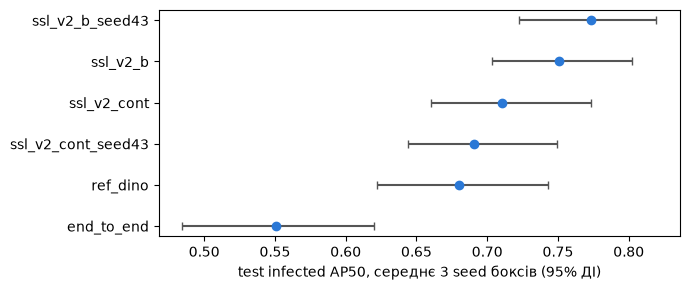

In [5]:
t = t.sort_values('AP50')
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(t['AP50'], range(len(t)), xerr=[t['AP50'] - t['AP50_lo'], t['AP50_hi'] - t['AP50']],
            fmt='o', color='#2a78d6', ecolor='#555555', capsize=3)
ax.set_yticks(range(len(t)), t.index)
ax.set_xlabel('test infected AP50, середнє 3 seed боксів (95% ДІ)')
plt.tight_layout()

## Парні різниці на тих самих боксах

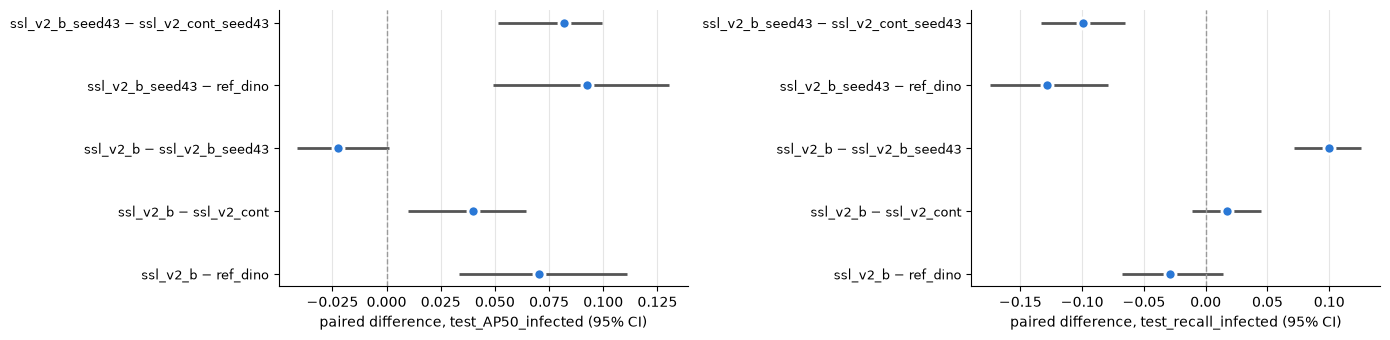

In [6]:
p = pd.read_csv(T / 'phase7_two_stage_seed2_diff.csv')
p = p[(p['run'] == 'a_3s') & (p['training'] == 'clean') & p['comparison'].str.endswith('(two-stage, a_3s)')].copy()
p[['a', 'b']] = p['comparison'].str.replace(' (two-stage, a_3s)', '', regex=False).str.split(' - ', expand=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
plot_paired_diffs(p, 'test_AP50_infected', axes[0])
plot_paired_diffs(p, 'test_recall_infected', axes[1])
plt.tight_layout()

## Probe на тестових фолдах (AUPRC infected)

b2 вищий за DINO за linear і нижчий за kNN.

In [7]:
f = pd.read_csv(T / 'phase7_seed2_folds_runs.csv')
wide(f[f['eval'] == 'avg'], 'encoder', 'metric')

metric,knn_auprc,linear_auprc
encoder,,
b,"0.807 [0.754, 0.865]","0.935 [0.913, 0.957]"
b2,"0.848 [0.807, 0.894]","0.951 [0.930, 0.968]"
cont2,"0.816 [0.765, 0.869]","0.940 [0.916, 0.963]"
dino,"0.925 [0.891, 0.956]","0.910 [0.879, 0.943]"
